**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: ALEJANDRA EDITH TOBIAS VILLA
*   MATRÍCULA: A01840886

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto? 8 numericas, 5 de tipo object.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
DIR = "/content/drive/MyDrive/Colab Notebooks/MNA/TC5053 - Ciencia y analítica de datos/Actividad4EDA"
os.chdir(DIR)

In [4]:
loan_df = pd.read_csv('personal_loan.csv')

In [5]:
loan_df = loan_df.set_index('ID')
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial? Se eliminaron 59 registros, lo que representa el 1.17%.

In [6]:
registros_iniciales = len(loan_df)
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


In [7]:
#Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
loan_df = loan_df[loan_df['Age'] <= 100]

#Eliminando valores inválidos o inconsistentes de la columna Experience. No es posible tener números negativos.
loan_df = loan_df[loan_df['Experience'] >= 0]

#Eliminando valores inválidos o inconsistentes de la columna Family. No es posible tener números negativos.
loan_df = loan_df[loan_df['Family'] > 0]

#Eliminando valores no permitidos de Education. Solo valores 1, 2 o 3 son permitidos.
loan_df = loan_df[loan_df['Education'].isin([1, 2, 3])]

registros_finales = len(loan_df)
registros_eliminados = registros_iniciales - registros_finales
porcentaje_eliminados = (registros_eliminados / registros_iniciales) * 100

registros_eliminados, porcentaje_eliminados

(59, 1.171332142148104)

In [8]:
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,4978.000000,4978.000000,4978.000000,4978.000000,4978.000000,4978.000000,4978.000000,4978.000000
mean,45.583568,20.356971,73.946364,93150.353957,2.391322,1.940450,1.877260,56.664323
std,11.306085,11.298484,46.208482,2125.326340,1.148743,1.756744,0.839789,101.817348
min,24.000000,0.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000
25%,36.000000,11.000000,39.000000,91910.250000,1.000000,0.700000,1.000000,0.000000
50%,46.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000


3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [9]:
loan_df.describe(include=['object'])

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4978,4978,4978,4978,4978
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


In [10]:
loan_df.select_dtypes(include='object').apply(lambda x: x.value_counts())

,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,3475,1766,2213,374,2628
1,117,129,163,1276,557
No,1018,2693,2462,1628,885
Yes,368,390,140,1700,908


In [11]:
columnas_binarias = [
    'Personal Loan',
    'Securities Account',
    'CD Account',
    'Online',
    'CreditCard'
]

loan_df[columnas_binarias] = loan_df[columnas_binarias].replace({
    'Yes': '1',
    'No': '0'
})

In [12]:
loan_df.select_dtypes(include='object').apply(lambda x: x.value_counts())

,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,4493,4459,4675,2002,3513
1,485,519,303,2976,1465


4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [13]:
# Contar registros duplicados
loan_df.duplicated().sum()

np.int64(36)

In [14]:
# Eliminar registros duplicados
loan_df = loan_df.drop_duplicates()

# Reiniciar el índice
loan_df = loan_df.reset_index(drop=True)

In [15]:
#Comprobar que los duplicados fueron eliminados
loan_df.duplicated().sum()

np.int64(0)

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [16]:
# Nominal: ZIP Code como texto
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype('object')

# Ordinal: Education como categoría ordenada (1 < 2 < 3)
loan_df['Education'] = pd.Categorical(
    loan_df['Education'],
    categories=[1, 2, 3],
    ordered=True
)

# Binarias: convertir a category
columnas_binarias = [
    'Personal Loan',
    'Securities Account',
    'CD Account',
    'Online',
    'CreditCard'
]

loan_df[columnas_binarias] = loan_df[columnas_binarias].astype('category')

In [17]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4942 entries, 0 to 4941
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Age                 4942 non-null   int64   
 1   Experience          4942 non-null   int64   
 2   Income              4942 non-null   int64   
 3   ZIP Code            4942 non-null   object  
 4   Family              4942 non-null   int64   
 5   CCAvg               4942 non-null   float64 
 6   Education           4942 non-null   category
 7   Mortgage            4942 non-null   int64   
 8   Personal Loan       4942 non-null   category
 9   Securities Account  4942 non-null   category
 10  CD Account          4942 non-null   category
 11  Online              4942 non-null   category
 12  CreditCard          4942 non-null   category
dtypes: category(6), float64(1), int64(5), object(1)
memory usage: 300.1+ KB


In [18]:
# Variables numéricas
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Variables categóricas
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

La variable **Age** tiene una asimetría cercana a 0, por lo que se puede decir que es casi simétrica. La curtosis indica que tiene una distribución platicúrtica, es decir, una curtosis menor que la de una distribución normal.

La variable **Income** tiene una asimetría positiva, lo cual indica que la distribución presenta una cola hacia la derecha, asociada con algunos ingresos relativamente altos. La curtosis es cercana a 0, por lo que podemos decir que es mesocúrtica, similar a la curtosis de una distribución normal. Esto sugiere que hay ingresos altos.

La variable **Mortgage** tiene una asimetría positiva mayor que Income, lo que indica una cola más pronunciada hacia los valores altos. La curtosis es claramente leptocúrtica, con un valor aproximado de 4.76, lo que indica una mayor presencia de valores en las colas en comparación con una distribución normal. Por ello, convendría revisar si existen valores extremos que merezcan atención.

In [19]:
# Estadísticas descriptivas
loan_df[num_cols].describe()

,Age,Experience,Income,Family,CCAvg,Mortgage
count,4942.000000,4942.000000,4942.000000,4942.000000,4942.000000,4942.000000
mean,45.561311,20.336301,73.815864,2.391947,1.935585,56.652165
std,11.314736,11.307402,46.108226,1.148356,1.748332,101.868229
min,24.000000,0.000000,8.000000,1.000000,0.000000,0.000000
25%,36.000000,11.000000,39.000000,1.000000,0.700000,0.000000
50%,46.000000,20.000000,64.000000,2.000000,1.500000,0.000000
75%,55.000000,30.000000,98.000000,3.000000,2.600000,101.000000
max,67.000000,43.000000,224.000000,4.000000,10.000000,635.000000


In [20]:
# Simetría (skewness)
loan_df[num_cols].skew()

,0
Age,-0.023024
Experience,-0.015453
Income,0.842132
Family,0.159089
CCAvg,1.594922
Mortgage,2.104183


In [21]:
# Curtosis (kurtosis)
loan_df[num_cols].kurt()

,0
Age,-1.161379
Experience,-1.134596
Income,-0.046006
Family,-1.404189
CCAvg,2.636409
Mortgage,4.761586


7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.

Si coinciden. Sin embargo, los histogramas permiten visualizar más claramente cómo se distribuyen los datos. Por ejemplo, en la variable Mortgage, la asimetría positiva indica una cola hacia los valores de la izquierda, pero por si solo no sabes a qué datos se refiere. Al observar el histograma, podemos ver una gran concentración de clientes con hipotecas de valor cero y también la presencia de valores superiores a 100,000, lo que ayuda a comprender la forma de la distribución.

* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

Cuando la mediana es menor que la media, generalmente tenemos una asimetría positiva, como en el caso de Income y Mortgage. En cambio, cuando la media y la mediana son cercanas, la distribución puede ser aproximadamente simétrica, como sucede con Age.

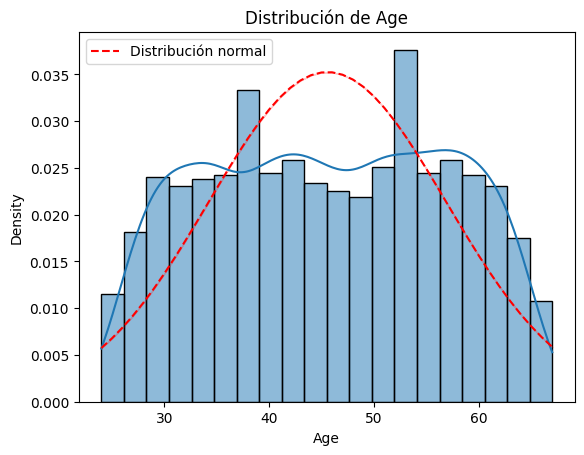

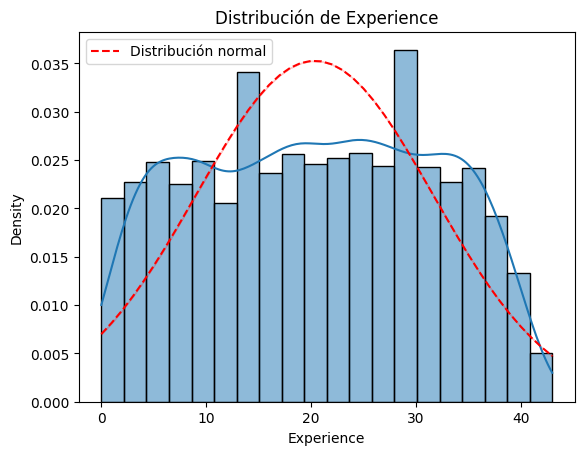

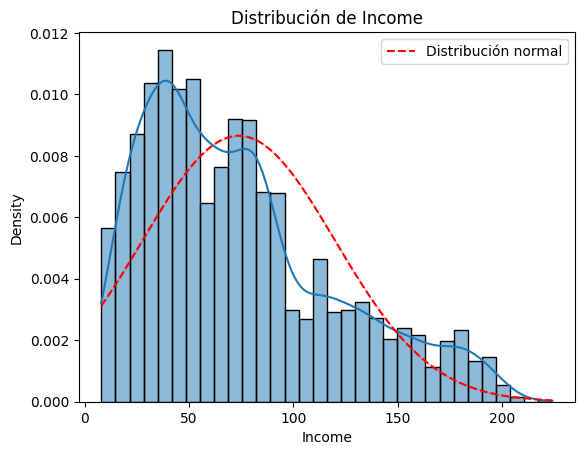

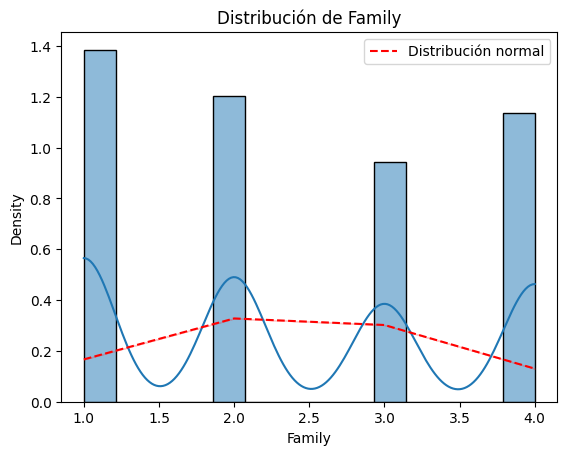

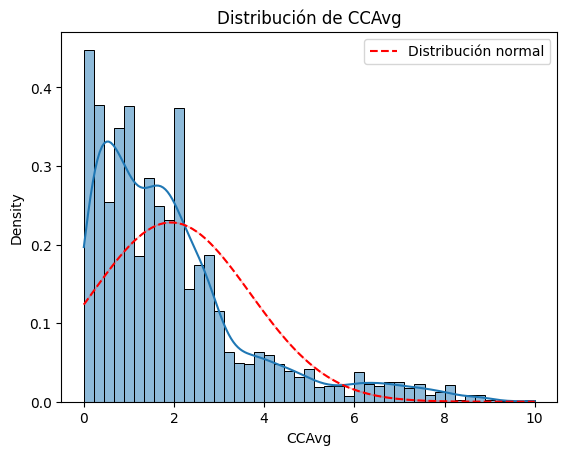

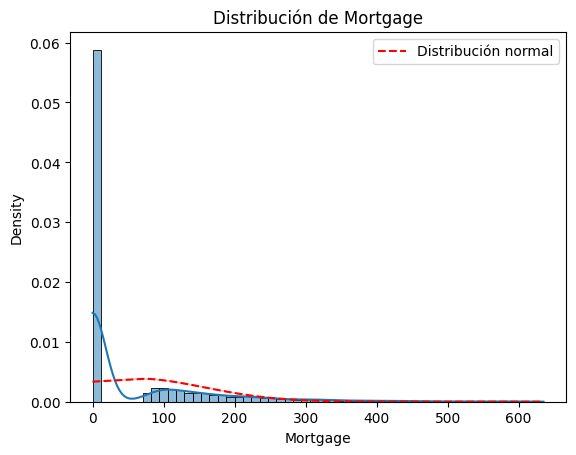

In [22]:
for col in num_cols:
    sns.histplot(loan_df[col], kde=True, stat='density')

    sns.lineplot(
    x=loan_df[col].dropna().sort_values(),
    y=norm.pdf(
        loan_df[col].dropna().sort_values(),
        loan_df[col].mean(),
        loan_df[col].std()
    ),
    color='red',
    linestyle='--',
    label='Distribución normal'
    )

    plt.title(f'Distribución de {col}')
    plt.show()

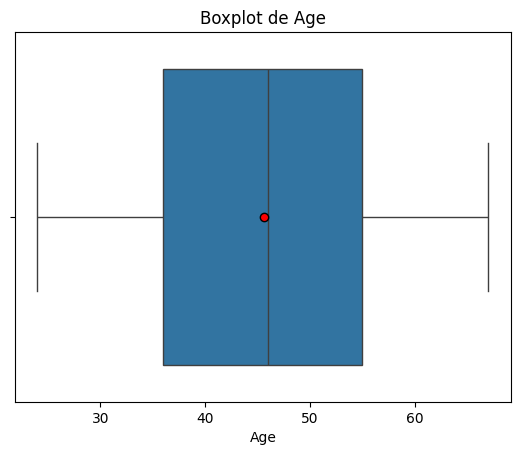

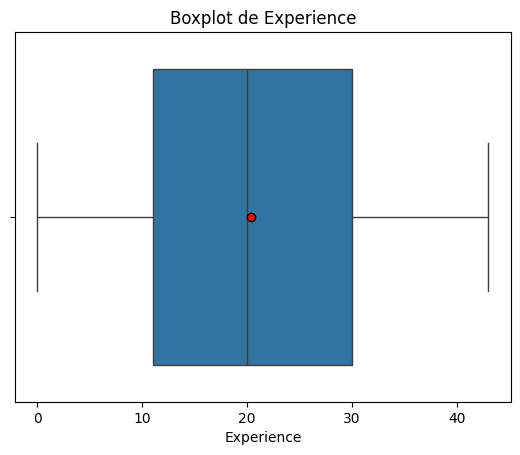

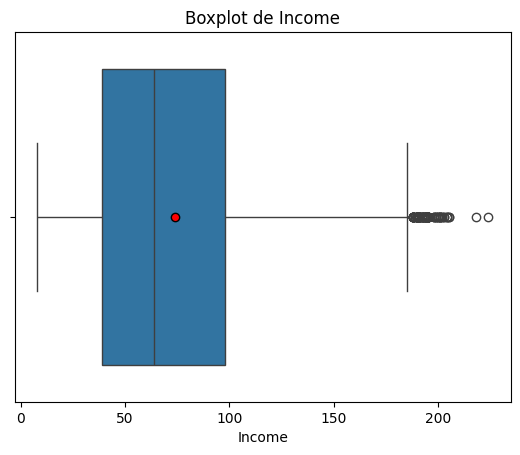

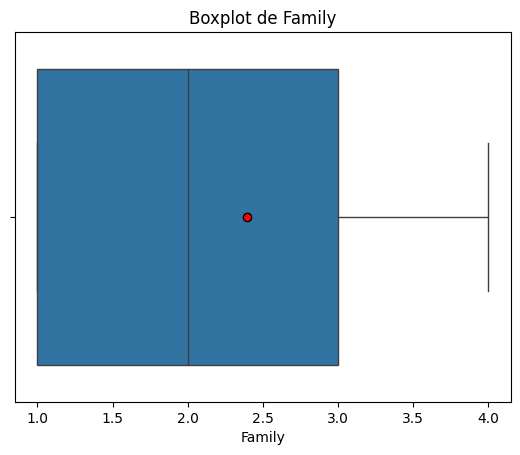

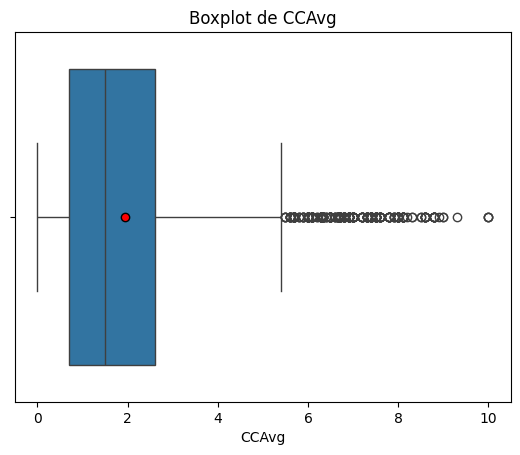

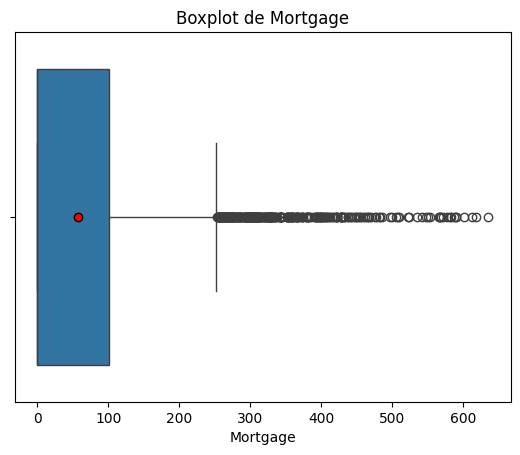

In [23]:
for col in num_cols:
    sns.boxplot(
        data=loan_df,
        x=col,
        showmeans=True,
        meanprops={
            'marker': 'o',
            'markerfacecolor': 'red',
            'markeredgecolor': 'black'
        }
    )
    plt.title(f'Boxplot de {col}')
    plt.show()

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [24]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4942,4942,4942,4942,4942,4942,4942
unique,468,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4463,4427,4641,2952,3489


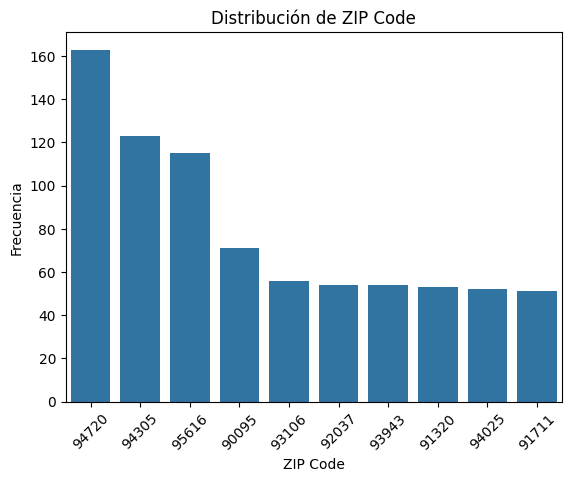

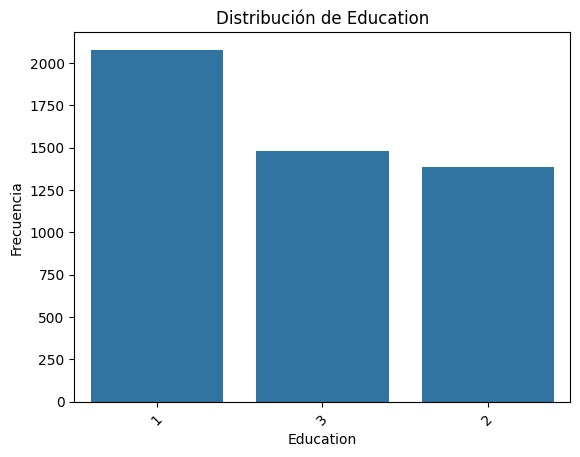

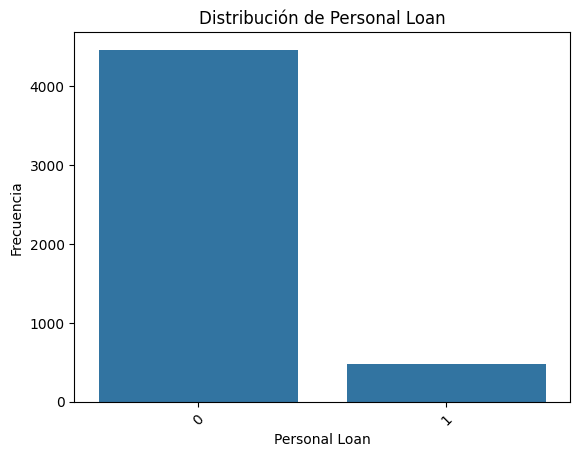

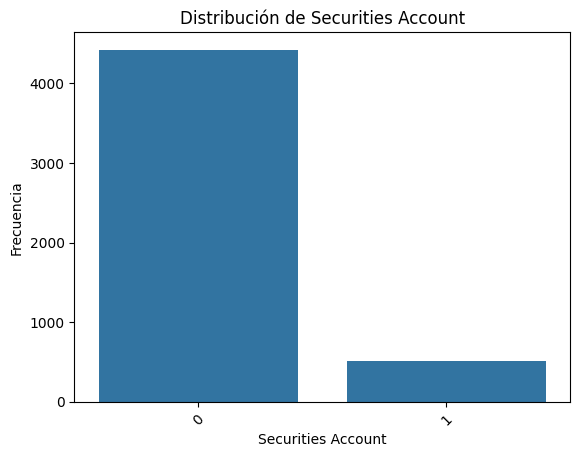

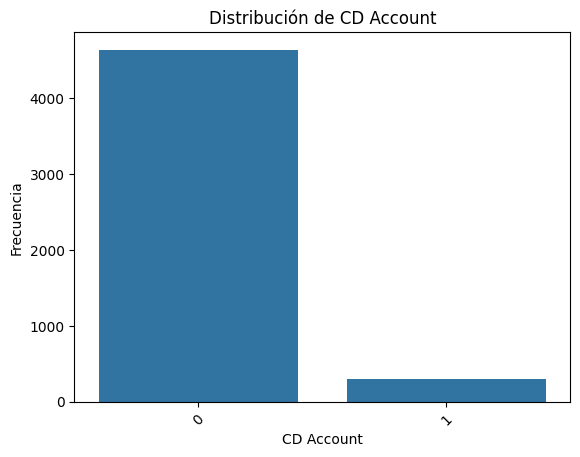

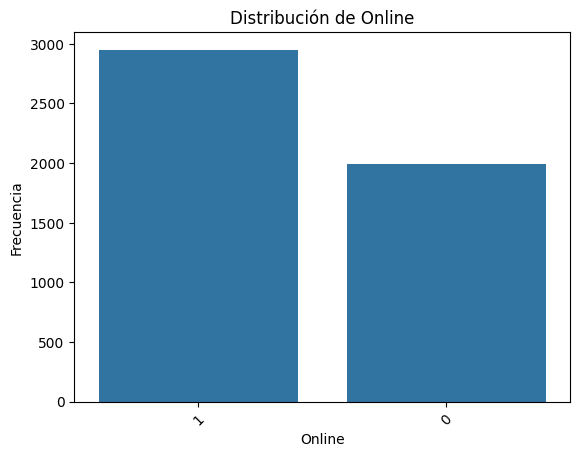

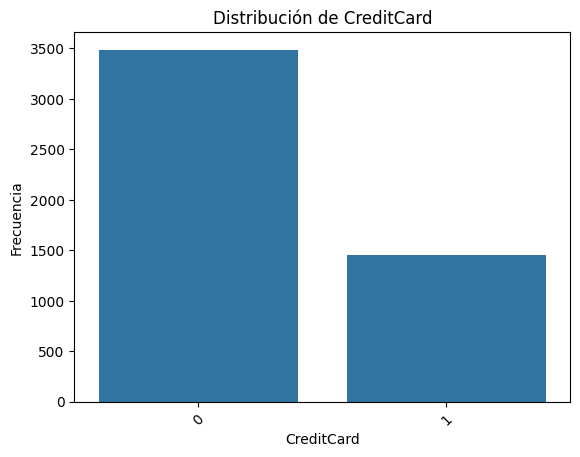

In [25]:
for col in cat_cols:
    conteo = loan_df[col].value_counts().head(10)

    sns.barplot(x=conteo.index.astype(str), y=conteo.values)

    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.xticks(rotation=45)
    plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.

La matriz de dispersión muestra una relación positiva muy marcada entre la edad y los años de experiencia laboral. También se observa una posible relación positiva entre los ingresos, los gastos promedio en tarjeta de crédito y el monto de la hipoteca. En particular, los clientes con mayores ingresos presentan una mayor variabilidad en sus gastos y algunos de los montos hipotecarios más altos. Sin embargo, estas relaciones no son perfectas y no permiten concluir que todos los clientes con mayores ingresos gasten más o tengan hipotecas más elevadas. Sería necesario analizar otras variables, como la aceptación del préstamo personal, para explorar estas hipótesis.

* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado? Si, en especial el valor alto entre Edad y Experiencia, al igual que la relación positiva entre ingresos y gastos en tarjeta de crédito ahora con ayuda del heatmap, es más evidente.

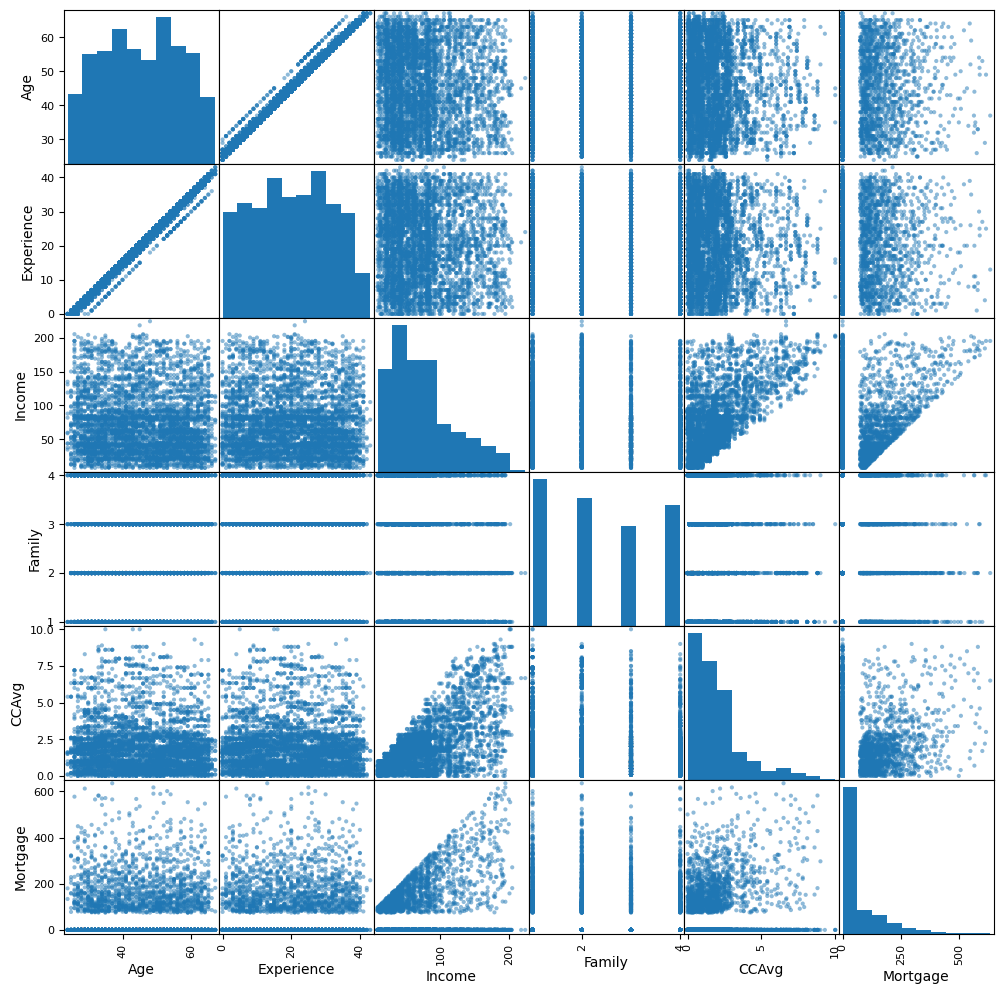

In [26]:
pd.plotting.scatter_matrix(
    loan_df[num_cols],
    figsize=(12, 12),
    diagonal='hist'
)

plt.show()

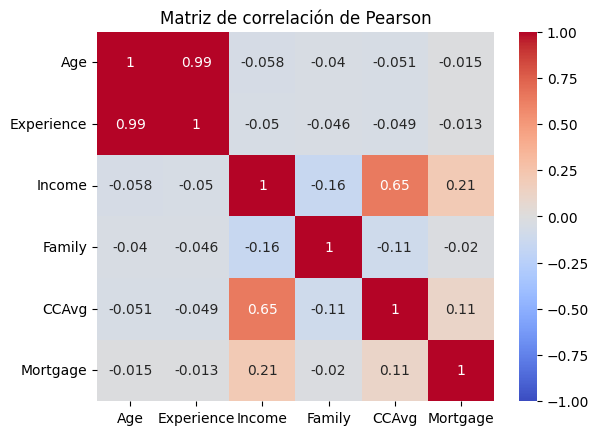

In [27]:
corr = loan_df[num_cols].corr(method='pearson')

sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación de Pearson')
plt.show()

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.

El primer hallazgo se observa en el boxplot de Family, donde la mediana del grupo que aceptó el préstamo personal es mayor que la del grupo que no lo aceptó. Esto sugiere una posible relación entre el tamaño de la familia y la aceptación del préstamo.

Por otra parte, en el boxplot de Mortgage se observan numerosos valores atípicos en el grupo que no aceptó el préstamo personal, incluidos algunos de los montos hipotecarios más elevados. No obstante, se requiere un análisis adicional para determinar si existe una relación entre el monto de la hipoteca y la aceptación del préstamo.

Adicionalmente, en las variables categóricas se observa que hay mayor población en nivel de educación Universidad y Posgrado que si aceptaron el préstamo, y finalmente hay una mayor población de aceptación en personas que cuentan con CD Account.


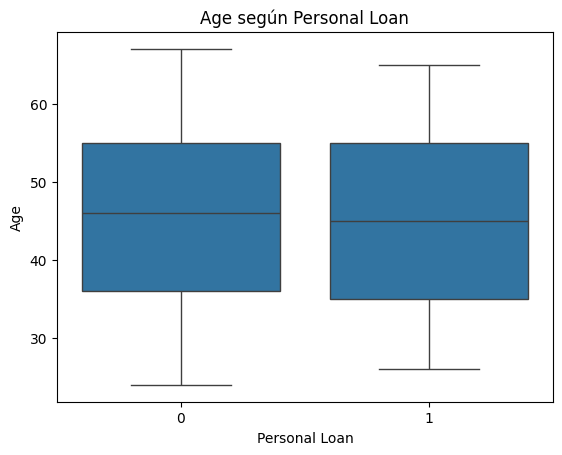

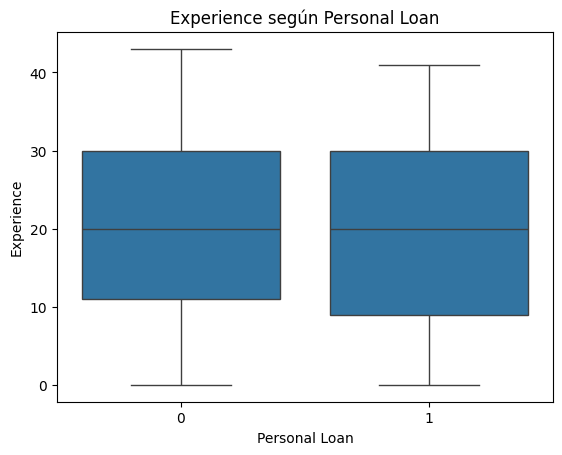

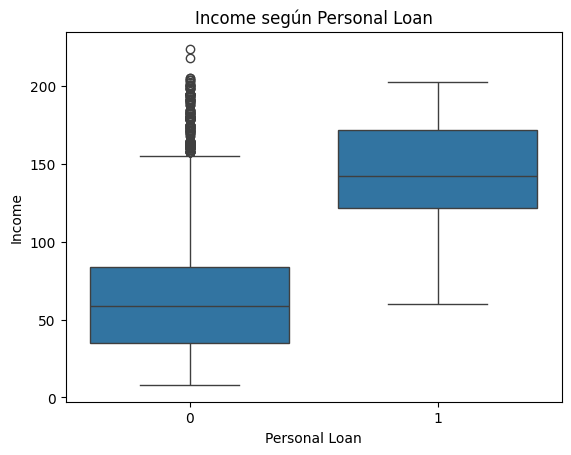

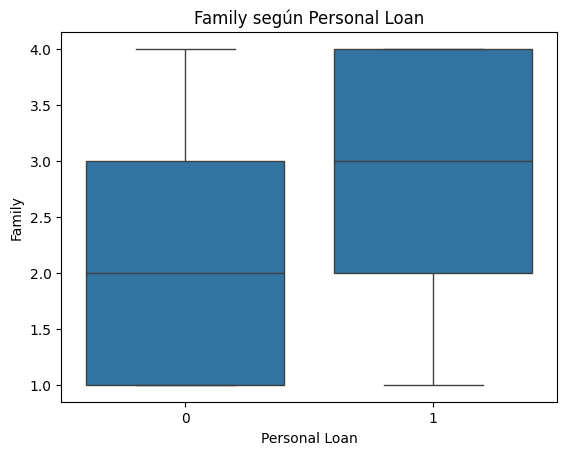

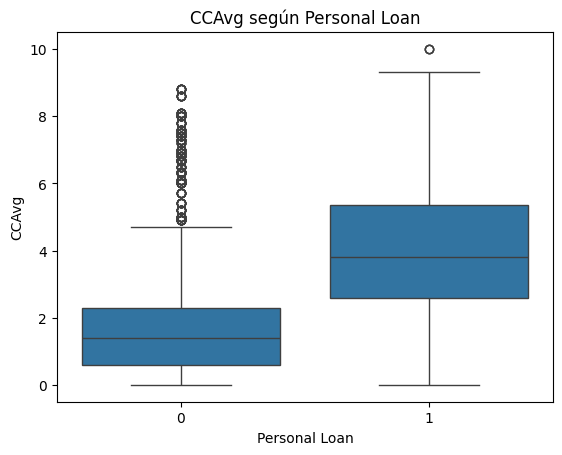

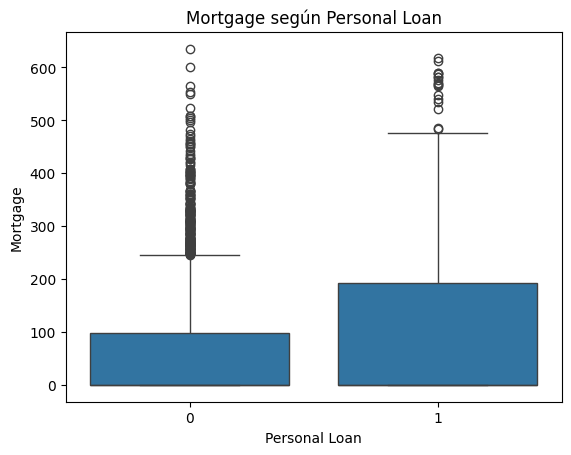

In [28]:
#Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de Personal Loan.
for col in num_cols:
    sns.boxplot(data=loan_df, x='Personal Loan', y=col)
    plt.title(f'{col} según Personal Loan')
    plt.show()

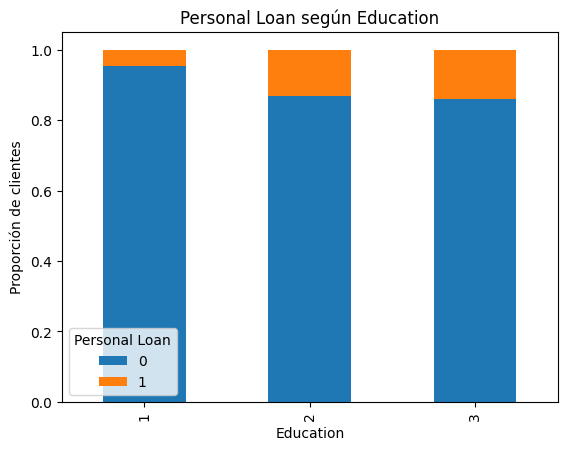

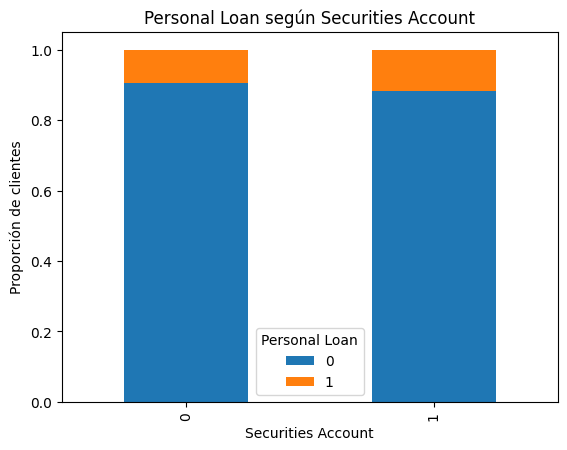

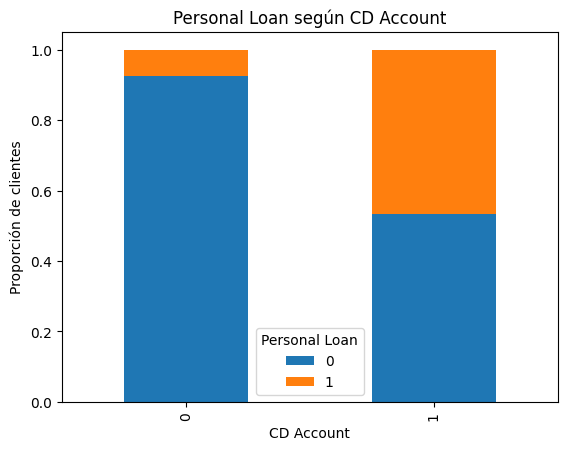

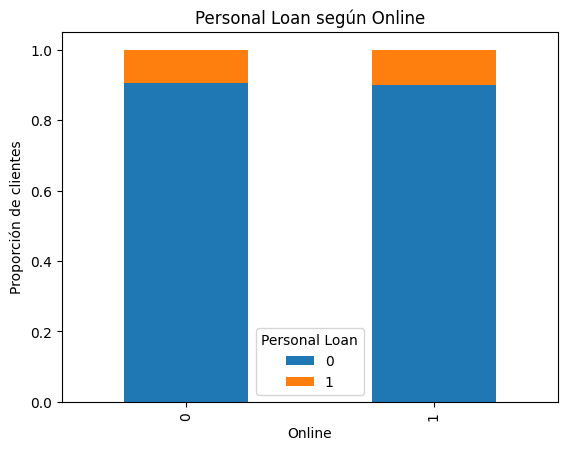

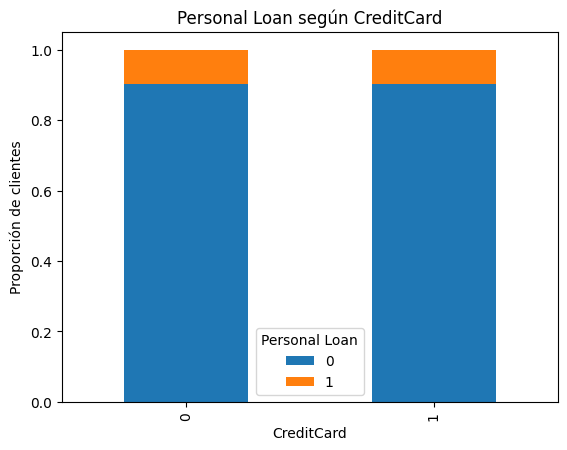

In [29]:
#Variables categóricas (sin considerar ZIP Code): Genera gráficos de barras apiladas que muestren la distribución relativa de Personal Loan dentro de cada categoría de la variable.
for col in cat_cols:
    if col not in ['ZIP Code', 'Personal Loan']:
        tabla = pd.crosstab(
            loan_df[col],
            loan_df['Personal Loan'],
            normalize='index'
        )

        tabla.plot(kind='bar', stacked=True)
        plt.title(f'Personal Loan según {col}')
        plt.ylabel('Proporción de clientes')
        plt.xlabel(col)
        plt.legend(title='Personal Loan')
        plt.show()

---

**Declaración de uso de IA**

*   OpenAI. (2026). *ChatGPT GPT-6, utilizado para generación de código y depuración. https://chat.openai.com/

---